<a href="https://colab.research.google.com/github/ivorywang-1005/intro-to-urban-data/blob/main/Scale/S07_Analyzing_proximity_with_apply_functions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **07 Scale**  Analyzing proximity with apply functions

```
    Class       ARCH 6131 Urban Design Methods / Skills / Tools 1
                Tata Innovation Center
                Fall 2025
                Monday 9:30 AM to 12 PM

    Instructor  Brian Ho
                brian@brian-ho.io
```

This notebook is a quick demonstration of how you can analyze proximity of objects in one dataset to another, and return the result in an `apply()` function.

In [1]:
# Connect to Google Drive
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [6]:
# Set the path to the data directory
DATA_DIRECTORY = "/content/drive/MyDrive/ARCH 6131/Example Data"

In [3]:
import geopandas as gpd
from pathlib import Path
import matplotlib.pyplot as plt

To do this, let's use two datasets:
1. The sample vacant lots in Brooklyn ([link](https://github.com/brian-ho/intro-to-urban-data/blob/main/example_data/brooklyn_city_vacant_lots.geojson))

2. A set of trees in Brooklyn ([link](https://github.com/brian-ho/intro-to-urban-data/blob/main/example_data/trees.geojson))

Assume that we want to add to each lot a column which indicates how many trees are within 2,500 feet. Let's start by loading in the data.

In [8]:
vacant_lots_gdf = gpd.read_file(
    Path(DATA_DIRECTORY) / "brooklyn_city_vacant_lots.geojson"
)
trees_gdf = gpd.read_file(Path(DATA_DIRECTORY) / "trees.geojson")

In [9]:
print(f"There are {len(vacant_lots_gdf)} vacant lots, in {vacant_lots_gdf.crs.name}.")
print(f"There are {len(trees_gdf)} trees, in {trees_gdf.crs.name}.")

There are 1008 vacant lots, in WGS 84.
There are 10000 trees, in WGS 84.


Since we want to buffer in feet, we need to re-project this data to the right CRS.

<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

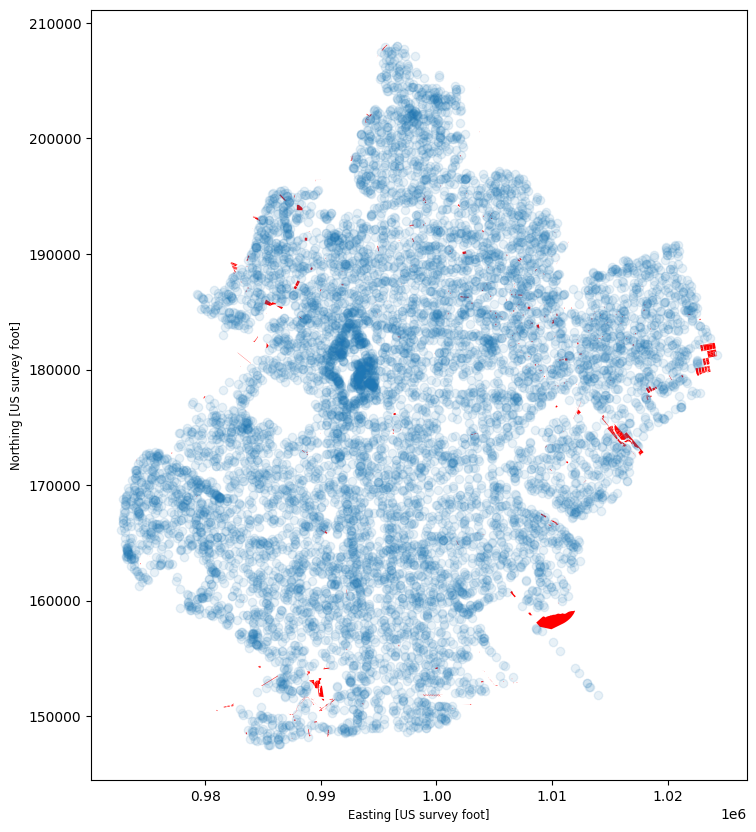

In [10]:
vacant_lots_gdf.to_crs(2263, inplace=True)
trees_gdf.to_crs(2263, inplace=True)

_, ax = plt.subplots(figsize=(10, 10))
vacant_lots_gdf.plot(ax=ax, color="red")
trees_gdf.plot(ax=ax, alpha=0.1)

OK! So counting the number of trees can be done with an `apply()` function on the vacant lots dataset, referencing the trees dataset. We'll want to see how many trees intersect an area buffered out from each lot.

While we could do the buffering in the apply function, this is actually pretty slow. It's faster if we pre-buffer the geometry in a GeoDataFrame and use it directly. Then, it's as simple as using the `intersects()` method to get a filtered list of trees we can count.

In [11]:
buffered_lots_gdf = vacant_lots_gdf.copy()
buffered_lots_gdf["geometry"] = buffered_lots_gdf["geometry"].buffer(2500)


def count_trees(geom):
    trees_near_lot = trees_gdf[trees_gdf["geometry"].intersects(geom)]
    return len(trees_near_lot)

That's it — just have to run it and look at the results.

In [19]:
vacant_lots_gdf["trees_near_lot"] = buffered_lots_gdf["geometry"].apply(count_trees)
vacant_lots_gdf["trees_near_lot"].describe()

,trees_near_lot
count,1008.000000
mean,102.217262
std,41.657890
min,3.000000
25%,71.750000
50%,105.500000
75%,135.000000
max,321.000000


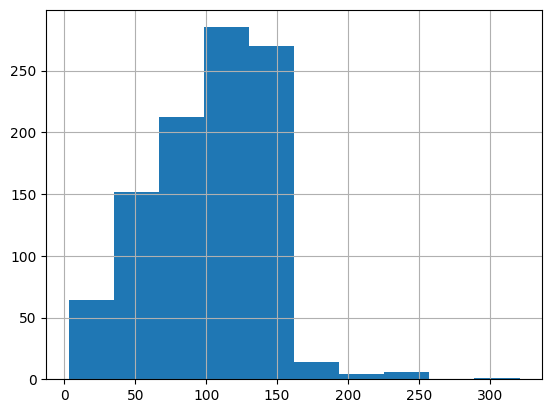

In [23]:
vacant_lots_gdf["trees_near_lot"].hist()

In [21]:
vacant_lots_gdf.iloc[0]

,0
Borough,BK
Block,199
Lot,100
CD,302
BCT2020,3000301
...,...
Notes,None
Shape_Leng,0.0
Shape_Area,68050.98009
geometry,"POLYGON ((984282.760437011 193230.47736882942,..."


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

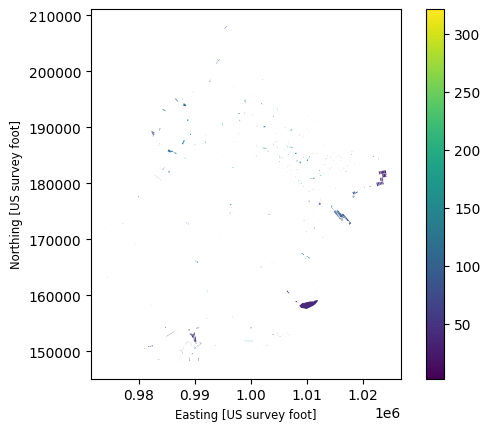

In [24]:
vacant_lots_gdf.plot(column="trees_near_lot", legend=True)

Looks good — as simple as that!

In [25]:
vacant_lots_gdf

,Borough,Block,Lot,CD,BCT2020,BCTCB2020,CT2010,CB2010,SchoolDist,Council,...,PFIRM15_FL,Version,DCPEdited,Latitude,Longitude,Notes,Shape_Leng,Shape_Area,geometry,trees_near_lot
0,BK,199,100,302,3000301,30003015000,3.01,5002,13,1,...,1,23v2,None,40.696810,-73.999888,None,0.0,68050.980090,"POLYGON ((984282.76 193230.477, 984293.276 193...",106
1,BK,314,42,306,3004700,30047001003,47,1002,15,39,...,None,23v2,t,40.687326,-74.002077,None,0.0,998.300417,"POLYGON ((983692.535 189708.212, 983682.141 18...",101
2,BK,330,4,306,3005100,30051001002,51,1002,15,39,...,None,23v2,t,40.685240,-74.002297,None,0.0,2031.729951,"POLYGON ((983663.676 188920.491, 983656.658 18...",104
3,BK,330,112,306,3005100,30051001002,51,1002,15,39,...,None,23v2,t,40.685295,-74.002055,None,0.0,386.532939,"POLYGON ((983692.982 188954.247, 983686.335 18...",102
4,BK,340,1,306,3005303,30053031000,53,1000,15,39,...,1,23v2,t,40.684793,-74.006580,None,0.0,1062.265150,"POLYGON ((982428.318 188739.603, 982408.606 18...",60
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1003,BK,8866,5540,315,3062800,30628004027,628,4033,22,46,...,1,23v2,t,40.586728,-73.926218,None,0.0,4492.011509,"MULTIPOLYGON (((1004642.954 153192.816, 100465...",24
1004,BK,8876,2850,315,3062800,30628004025,628,4036,22,46,...,1,23v2,None,40.588351,-73.927570,None,0.0,74.447124,"POLYGON ((1004363.346 153662.745, 1004373.224 ...",28
1005,BK,8876,5545,315,3062800,30628004025,628,4036,22,46,...,1,23v2,t,40.587920,-73.927481,None,0.0,683.346874,"MULTIPOLYGON (((1004410.105 153558.129, 100440...",28
1006,BK,8883,530,315,3062800,30628001013,628,1028,22,46,...,1,23v2,t,40.588972,-73.928639,None,0.0,1449.231933,"MULTIPOLYGON (((1004009.531 153953.559, 100406...",40
